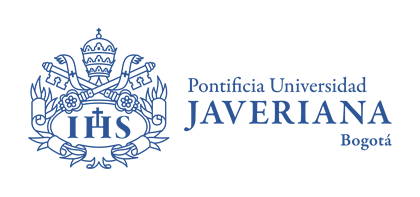

# Aprendizaje de máquina - Ejercicio k-means
El objetivo de este notebook es familiarizar al estudiante con el algoritmo k-means

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from sklearn.metrics import pairwise_distances

# Aca ponemos una semilla, de forma que cuando se reproduzca varias veces el codigo, de el mismo resultado
np.random.seed(42)

## Creación de un dataset aleatorio

Vamos a crear inicialmente un dataset sobre el cuál vamos a trabajar, vamos a trabajar inicialmente con puntos tomados de 3 distribuciones normales con parámetros diferentes.

In [38]:
# Centros de la distribución 1 sobre cada dimensión
means_1 =[0,0,0]
# Matriz de covarianza 1
cov_1=[[0.1,0,0],[0,0.1,0],[0,0,0.1]]
X1=np.random.multivariate_normal(means_1,cov_1,500)
print(X1.shape)
# Centros de la distribución 2 sobre cada dimensión
means_2 =[1,1,1]
# Matriz de covarianza 2
cov_2=[[0.2,0,0],[0,0.2,0],[0,0,0.2]]
X2=np.random.multivariate_normal(means_2,cov_2,500)
print(X2.shape)

# Centros de la distribución 3 sobre cada dimensión
means_3 =[-1,-1,-1]
# Matriz de covarianza 2
cov_3=[[0.25,0,0],[0,0.25,0],[0,0,0.25]]
X3=np.random.multivariate_normal(means_3,cov_2,500)
print(X3.shape)

(500, 3)
(500, 3)
(500, 3)


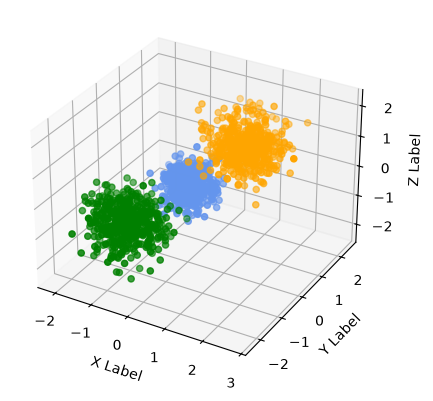

In [39]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(X1[:,0], X1[:,1], X1[:,2], c='cornflowerblue')
ax.scatter(X2[:,0], X2[:,1], X2[:,2], c='orange')
ax.scatter(X3[:,0], X3[:,1], X3[:,2], c='green')
ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')

plt.show()

In [40]:
# concatenamos los 3 datasets y los "desordena"
X=np.concatenate([X1,X2,X3])
np.random.shuffle(X)

In [41]:
X.shape

(1500, 3)

Text(0.5, 0, 'Z Label')

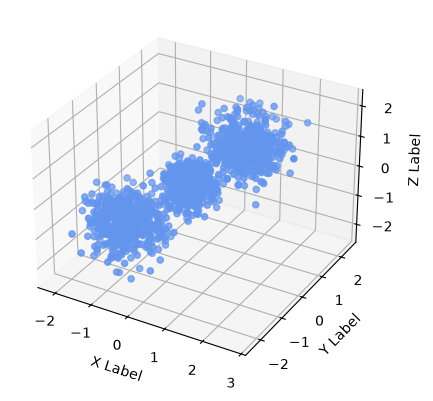

In [42]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(X[:,0], X[:,1], X[:,2], c='cornflowerblue')
ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')

Recordemos los pasos que debemos seguir para implementar K-means


1.   Inicializar los centroides representantes de cada grupo aleatoriamente
2.   Asignar cada instancia al cluster cuyo centroide sea el más cercano
3.   Actualizar los centroides
4.   Repetir hasta convergencia





## Inicialización centroides

Comencemos con la implementación de funciones para solucionar subproblemas. La primera función que vamos a definir es la inicialización de los centroides. Los puntos creados aleatoriamente deberían estar entre el mínimo y máximo de los datos conocidos en cada dimensión. Para definir la función `init_centroids` se puede apoyar de los siguientes fragmentos de código:

In [43]:
# Valores mínimos en cada dimensión
min_vals=np.min(X,axis=0)
print(min_vals)

[-2.13245488 -2.34505407 -2.30004465]


In [44]:

# Valores máximos en cada dimensión
max_vals=np.max(X,axis=0)
print(max_vals)

[2.75586688 2.42800112 2.20436127]


In [45]:
# Creación de 10 instancias aleatorias entre los límites mínimo y máximo
np.random.uniform(low=min_vals,high=max_vals, size=(10,len(min_vals)))

array([[-0.50485581, -1.74862949, -1.82009458],
       [ 1.23245868, -1.10504099, -1.15294505],
       [ 2.74704373, -1.4480731 , -1.6331234 ],
       [-1.65004973,  0.42238884,  0.52810888],
       [-0.34710326,  0.21050333,  1.25122686],
       [ 1.86670153,  2.22711313,  1.41279294],
       [ 0.62867181, -1.48754146, -1.85066909],
       [-1.86598322,  0.83631051,  1.33742644],
       [ 0.35415595, -2.0839003 ,  0.11193217],
       [ 2.4417886 ,  0.50738667,  1.34594532]])

In [46]:
def init_centroids(X,k):
  """
    Retorna una matriz numpy de tamaño (k,len(X[1]))
    con puntos aleatorios.


    Parameters:
    X: Matriz de instancias x características
    k: número de centroides a generar

    Returns:
    np.array Matriz de centroides.

  """
  min_vals = np.min(X, axis=0)
  max_vals = np.max(X, axis=0)
  centroids = np.random.uniform(low=min_vals, high=max_vals, size=(k, len(min_vals)))
  return centroids

In [47]:
# Correr para verificar
result=init_centroids(X,4)
print(result)
assert(result.shape==(4,X.shape[1]))
assert(np.all(X.min(axis=0)<=result.min(axis=0)))
assert(np.all(X.max(axis=0)>=result.max(axis=0)))

[[ 1.77894872  2.10404956  1.16937836]
 [ 1.52254581 -1.22766913 -2.03011743]
 [ 0.39773785 -1.75112273  2.03407615]
 [-0.71520935  1.72609568 -0.554026  ]]


## Asignación de puntos a cluster

Una vez inicializados los centroides, debemos establecer una forma para asignar cada instancia al centroide más cercano.

Al trabajar con datos es importante evitar al máximo iterar sobre los datos.

El algoritmo imperativo clásico para resolver este problema es cuadrático

```python
for i in X:
  dist_i = np.inf
  c_id= None
  for id, j in centroids:
    if dist(i,j) < dist_i:
      dist_i=dist(i,j)
      c_id=id
```

Para definir la función `closest_point` se puede apoyar de los siguientes fragmentos de código:

In [48]:
# Definimos matriz con 4 puntos para ejemplo
o1= np.array( [[1,1,1],[2,2,2],[3,3,3],[4,4,4]])
print(o1)
# Definimos matriz con 2 centroides para ejemplo
cent=np.array([[1.5,1.5,1.5],[3.5,3.5,3.5]])
print(cent)



[[1 1 1]
 [2 2 2]
 [3 3 3]
 [4 4 4]]
[[1.5 1.5 1.5]
 [3.5 3.5 3.5]]


In [49]:
# La función pariwise distances de sklearn permite comparar eficientemente las distancias entre los puntos de las 2 matrices
distances=pairwise_distances(o1,cent, metric='euclidean')
# El resultado es una matriz de distancias entre o1 y cada instancia de o2
distances


array([[0.8660254 , 4.33012702],
       [0.8660254 , 2.59807621],
       [2.59807621, 0.8660254 ],
       [4.33012702, 0.8660254 ]])

In [50]:
# Al llamar matriz.min(axis=1) obtenemos por cada punto qué distancia fue la menor

distances.min(axis=1)

array([0.8660254, 0.8660254, 0.8660254, 0.8660254])

In [51]:
# Al llamar matriz.argmin(axis=1) nos dice en qué coordenada esta el punto cuya distancia es mínima

distances.argmin(axis=1)

array([0, 0, 1, 1])

In [52]:
def closest_point(X,centroids):
  """
    Retorna una tupla donde la primera coordenada contiene un arreglo numpy con
    el identificador del punto más cercano de cada instancia a alguno de los
    centroides y la segunda tupla contiene un arreglo numpy con la distancia al
    identificador del punto más cercano


    Parameters:
    X: Matriz de instancias x características
    centroids: puntos centroides identificados

    Returns:
    tuple:  Posición 0, identificadores de punto más cercano
            Posición 1, distancias a los puntos
  """
  distances = pairwise_distances(X, centroids, metric='euclidean')
  closest_indices = distances.argmin(axis=1)
  closest_distances = distances.min(axis=1)
  return closest_indices, closest_distances

In [53]:
# Correr para verificar
from math import isclose

o_test= np.array( [[1,1,1],[2,2,2],[3,3,3],[4,4,4]])
cent_test=np.array([[1,1,1],[4,4,4]])
ids,dist=closest_point(o_test,cent_test)
assert((ids==[0,0,1,1]).all())
assert(dist[0]==0)
assert(isclose(dist[1],1.73205081,abs_tol=0.0001))
assert(isclose(dist[2],1.73205081,abs_tol=0.0001))
assert(dist[3]==0)

## Recalcular centroides

Una vez asignado cada punto a un centroide, hay que recalcular los centroides.

Revise los siguientes segmentos de código para completar la función solicitada

Aunque no es lo más eficiente, podemos solucionar rápidamente este problema utilizando pandas y la función groupby

In [54]:
X_pandas=pd.DataFrame(X)

In [55]:
X_pandas

,0,1,2
0,-0.404638,-0.197585,0.008251
1,0.263709,0.145205,-0.022188
2,0.561209,0.792312,1.206640
3,-1.298893,-1.027314,-1.473349
4,-0.788257,-1.119693,-0.621313
...,...,...,...
1495,0.186781,0.350603,0.259459
1496,-0.773725,-1.325693,-0.031757
1497,0.796277,0.602319,1.427223
1498,-1.539796,-1.480894,-0.250294


In [56]:
# Asignación aleatoria en 3 labels de los datos
X_pandas['label']=np.random.randint(1, 4, X_pandas.shape[0])

In [57]:
X_pandas.groupby('label').mean()

,0,1,2
label,,,
1,-0.026779,-0.042634,-0.025885
2,-0.019674,0.011475,0.042468
3,0.034441,0.010685,0.037058


In [58]:
# Para obtener de nuevo la matriz puede llamar values sobre el dataframe
X_pandas.groupby('label').mean().values

array([[-0.02677923, -0.04263439, -0.02588509],
       [-0.01967374,  0.01147519,  0.04246789],
       [ 0.03444127,  0.01068484,  0.03705764]])

In [59]:
def new_centers(X,labels):
  """
    Retorna matriz numpy con los nuevos centroides, dada la asignación de cada punto a un cluster


    Parameters:
    X: Matriz de instancias x características
    labels: instancias asignadas

    Returns:
    np.array:  Matriz con los nuevos centroides
  """
  df = pd.DataFrame(X)
  df['label'] = labels
  return df.groupby('label').mean().values

In [60]:
# Correr para verificar
from math import isclose

o_test= np.array( [[1,1,1],[2,2,2],[3,3,3],[4,4,4]])
cent_test=np.array([[1,1,1],[4,4,4]])
ids,dist=closest_point(o_test,cent_test)
centers=new_centers(o_test,ids)
assert((centers[0]==[1.5,1.5,1.5]).all())
assert((centers[1]==[3.5, 3.5, 3.5]).all())

# Implementación k-means

Una vez implementadas estas tres funciones, podemos verificar cómo funciona k-means

In [61]:
# Busquemos 2 centroides iniciales
centroides_iniciales=init_centroids(X,2)

In [62]:
print(centroides_iniciales)

[[ 2.29609073  0.36034275 -0.70357513]
 [-0.26928628 -0.3792604   0.97726795]]


In [63]:
#asignación de puntos a centroides
labels, distancias=closest_point(X,centroides_iniciales)

Text(0.5, 0, 'Z Label')

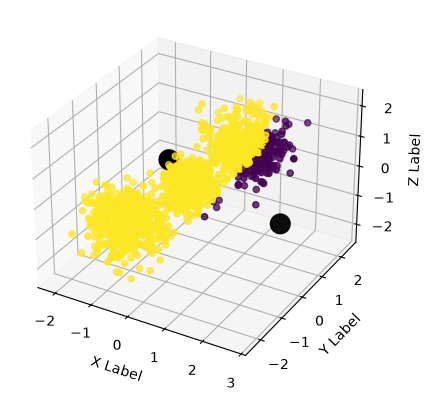

In [64]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(X[:,0], X[:,1], X[:,2], c=labels,cmap='viridis')
ax.scatter(centroides_iniciales[:, 0], centroides_iniciales[:, 1], centroides_iniciales[:,2], c='black',s=200)
ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')

In [65]:
centroides_nuevos=new_centers(X, labels)


In [66]:
#asignación de puntos a centroides
nuevos_labels, distancias=closest_point(X,centroides_iniciales)

Text(0.5, 0, 'Z Label')

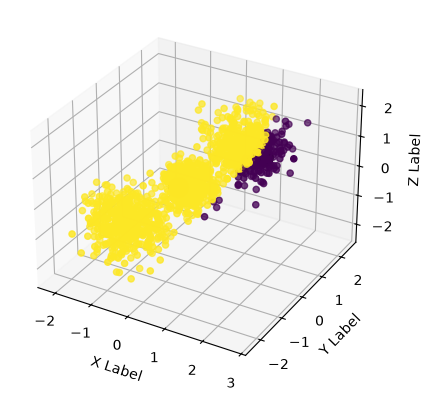

In [67]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(X[:,0], X[:,1], X[:,2], c=nuevos_labels,cmap='viridis')
ax.scatter(centroides_nuevos[:, 0], centroides_nuevos[:, 1], centroides_nuevos[:,2], c='black',s=200)
ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')

# Ejercicio:

Terminar el ejericio de implementación de k-means

Reflexione sobre las siguientes preguntas para su implementación:
  ¿Cúantas veces tenemos que repetir la asignación?
  ¿Cómo determinar que ya finalizamos?

El algoritmo convergió en la iteración 7

--- Coordenadas de los Centroides Finales ---
Centroide del Cluster 0: [1.00252362 1.0154596  1.01942111]
Centroide del Cluster 1: [ 0.03482701 -0.01308815  0.01710919]
Centroide del Cluster 2: [-1.05699983 -1.0317963  -0.99312029]


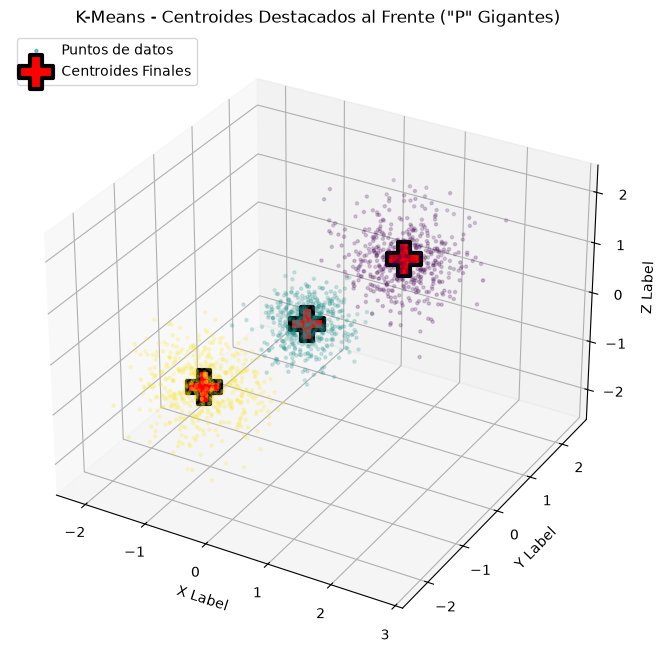

In [ ]:
# Parámetros del algoritmo
k = 3
max_iter = 100

centroides = init_centroids(X, k)

for i in range(max_iter):
    labels, distancias = closest_point(X, centroides)

    centroides_anteriores = centroides.copy()

    centroides = new_centers(X, labels)

    if np.allclose(centroides, centroides_anteriores, atol=1e-5):
        print(f"El algoritmo convergió en la iteración {i+1}")
        break

print("\nCoordenadas de los Centroides Finales\n")
for idx, cent in enumerate(centroides):
    print(f"Centroide del Cluster {idx}: {cent}")

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

ax.scatter(X[:,0], X[:,1], X[:,2], c=labels, cmap='viridis', alpha=0.5, s=5, label='Puntos de datos')

ax.scatter(centroides[:, 0], centroides[:, 1], centroides[:, 2], c='red', s=600, marker='P', depthshade=False, edgecolors='black', linewidths=3, label='Centroides Finales')

ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')
plt.title('K-Means - Centroides Destacados al Frente ("P" Gigantes)')
plt.legend(loc='upper left')
plt.show()

# Visualizacion

Como extra, tambien se puede generar una grafica 3D interactiva de los datos, para esto usamos plotly y numpy


In [ ]:

# Crear la figura interactiva en 3D con Plotly
fig = go.Figure()

for cluster_id in np.unique(labels):
    idx_puntos = (labels == cluster_id)
    fig.add_trace(go.Scatter3d(
        x=X[idx_puntos, 0],
        y=X[idx_puntos, 1],
        z=X[idx_puntos, 2],
        mode='markers',
        marker=dict(
            size=3,
            opacity=0.6
        ),
        name=f'Clúster {cluster_id}'
    ))

fig.add_trace(go.Scatter3d(
    x=centroides[:, 0],
    y=centroides[:, 1],
    z=centroides[:, 2],
    mode='markers',
    marker=dict(
        size=10,
        color='black',
        symbol='cross',
        line=dict(color='white', width=2)
    ),
    name='Centroides Finales'
))

fig.update_layout(
    title="Visualización Interactiva 3D de Clústeres y Centroides Finales",
    scene=dict(
        xaxis_title='Eje X',
        yaxis_title='Eje Y',
        zaxis_title='Eje Z'
    ),
    margin=dict(l=0, r=0, b=0, t=40),
    legend=dict(yanchor="top", y=0.9, xanchor="left", x=0.1)
)

fig.show()

### Método del Codo (Elbow Method)

Para determinar el número óptimo de clústeres sin depender de conocer la distribución original, evaluamos la suma de las distancias al cuadrado de cada punto a su centroide asignado (Inercia o WCSS) para un rango de valores de $k$. El punto donde la disminución de la inercia se aplana notablemente (el "codo") representa un balance ideal entre la complejidad (número de clústeres) y la calidad de la agrupación.

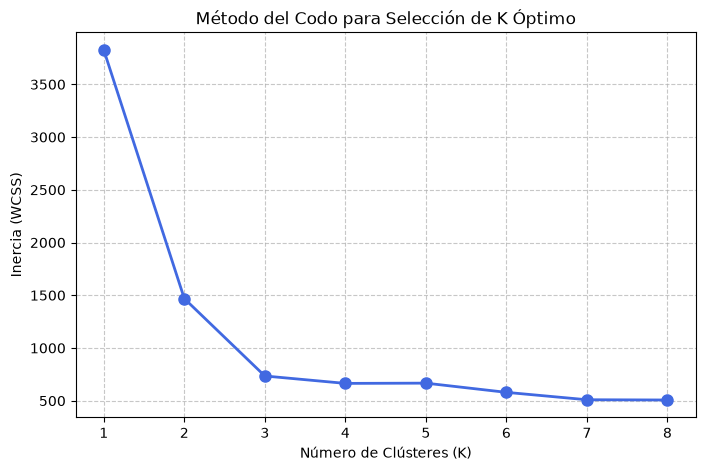

In [ ]:
def calcular_inercia(X, centroides, labels):
    """
    Calcula la inercia (suma de distancias al cuadrado de los puntos a sus respectivos centroides)
    """
    inercia = 0.0
    for idx, centroide in enumerate(centroides):
        puntos_cluster = X[labels == idx]
        if len(puntos_cluster) > 0:
            distancias_sq = np.sum((puntos_cluster - centroide) ** 2)
            inercia += distancias_sq
    return inercia

def new_centers_safe(X, labels, k):
    """
    Calcula nuevos centroides de forma segura para evitar clústeres vacíos
    """
    df = pd.DataFrame(X)
    df['label'] = labels
    grupos = df.groupby('label').mean()

    grupos = grupos.reindex(range(k))
    nuevos = grupos.to_numpy(copy=True)
    return nuevos

rango_k = range(1, 9)
inercias = []
resultados_k = {} 

for k_test in rango_k:
    centroides_test = init_centroids(X, k_test)

    for _ in range(50):
        labels_test, _ = closest_point(X, centroides_test)
        centroides_anteriores = centroides_test.copy()

        nuevos = new_centers_safe(X, labels_test, k_test)
        vacios = np.isnan(nuevos).any(axis=1)
        nuevos[vacios] = centroides_anteriores[vacios]

        centroides_test = nuevos

        if np.allclose(centroides_test, centroides_anteriores, atol=1e-5):
            break

    labels_test, _ = closest_point(X, centroides_test)
    val_inercia = calcular_inercia(X, centroides_test, labels_test)
    inercias.append(val_inercia)
    resultados_k[k_test] = (centroides_test, labels_test, val_inercia)

plt.figure(figsize=(8, 5))
plt.plot(rango_k, inercias, marker='o', color='royalblue', linewidth=2, markersize=8)
plt.title('Método del Codo para Selección de K Óptimo')
plt.xlabel('Número de Clústeres (K)')
plt.ylabel('Inercia (WCSS)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Visualización 3D por número de clústeres

Usando los resultados guardados en el método del codo, la siguiente gráfica interactiva permite seleccionar el valor de $k$ con el deslizador y ver cómo queda la agrupación de los datos y la ubicación de los centroides para cada caso, junto con su WCSS.


In [ ]:
import plotly.express as px

colores = px.colors.qualitative.Plotly
fig = go.Figure()
trazas_por_k = {} 
for k_test in rango_k:
    centroides_k, labels_k, _ = resultados_k[k_test]
    inicio = len(fig.data)

    for cluster_id in range(k_test):
        idx_puntos = (labels_k == cluster_id)
        fig.add_trace(go.Scatter3d(
            x=X[idx_puntos, 0],
            y=X[idx_puntos, 1],
            z=X[idx_puntos, 2],
            mode='markers',
            marker=dict(size=3, opacity=0.6, color=colores[cluster_id % len(colores)]),
            name=f'Clúster {cluster_id}',
            visible=False
        ))

    fig.add_trace(go.Scatter3d(
        x=centroides_k[:, 0],
        y=centroides_k[:, 1],
        z=centroides_k[:, 2],
        mode='markers',
        marker=dict(size=10, color='black', symbol='cross', line=dict(color='white', width=2)),
        name='Centroides',
        visible=False
    ))

    trazas_por_k[k_test] = range(inicio, len(fig.data))

pasos = []
for k_test in rango_k:
    visibles = [i in trazas_por_k[k_test] for i in range(len(fig.data))]
    pasos.append(dict(
        method='update',
        label=str(k_test),
        args=[{'visible': visibles},
              {'title': f'Clústeres para K = {k_test} (WCSS = {resultados_k[k_test][2]:.2f})'}]
    ))

k_inicial = rango_k[0]
for i in trazas_por_k[k_inicial]:
    fig.data[i].visible = True

fig.update_layout(
    title=f'Clústeres para K = {k_inicial} (WCSS = {resultados_k[k_inicial][2]:.2f})',
    scene=dict(
        xaxis_title='Eje X',
        yaxis_title='Eje Y',
        zaxis_title='Eje Z'
    ),
    sliders=[dict(active=0, currentvalue=dict(prefix='K = '), pad=dict(t=30), steps=pasos)],
    margin=dict(l=0, r=0, b=0, t=40),
    legend=dict(yanchor="top", y=0.9, xanchor="left", x=0.1)
)

fig.show()


# Respuestas

**¿Cuántas veces tenemos que repetir la asignación?**

No hay un número de repeticiones fijo definido de antemano. K-Means busca minimizar la función objetivo $W = \sum_{j=1}^{k} \sum_{x \in C_j} \text{dist}(x, c_j)^2$, que corresponde a la suma de las distancias al cuadrado entre cada observación $x$ y el centroide $c_j$ del clúster $C_j$ al que fue asignada. Cada vez que se asignan los puntos al centroide más cercano y se recalculan los centroides, los puntos quedan más cerca de sus respectivos centroides y el valor de $W$ disminuye, lo que indica una mayor cohesión dentro de cada clúster. Por lo tanto, la asignación debe repetirse tantas veces como sea necesario hasta que ya no sea posible seguir reduciendo $W$; la cantidad exacta de repeticiones depende de los datos y de la posición inicial de los centroides.

**¿Cómo determinar que ya finalizamos?**

Sabemos que el algoritmo terminó cuando una nueva repetición ya no produce cambios: los puntos permanecen asignados a los mismos clústeres, los centroides se mantienen en la misma posición y, en consecuencia, el valor de $W$ deja de disminuir. En ese momento el agrupamiento se ha estabilizado y repetir la asignación no mejora la cohesión de los clústeres. En nuestra implementación esto se verifica comparando los centroides de cada iteración con los de la iteración anterior, y el ciclo se detiene cuando prácticamente no cambian.
